# Movie recommender: collaborative filtering vs a popularity baseline

**Task:** recommend 10 movies to each user and check, on ratings the model has not seen, how many of them the user actually went on to watch and rate.

**Models** (in `recsys.py`):

- **Popularity**: the most-rated movies the user has not seen yet. Any recommender has to beat this to be worth building.
- **Item-kNN**: item-based collaborative filtering. Two movies are similar if the same people rated both (cosine similarity, shrunk toward zero for movies with few ratings).
- **EASE**: a linear item-item model with a closed-form solution ([Steck, 2019](https://arxiv.org/abs/1905.03375)), a strong and simple baseline in recommender research.

**Metrics:** Precision@10 (share of the 10 recommendations the user rated later), Recall@10, NDCG@10 (rewards hits near the top of the list) and catalog coverage.

**Evaluation:** a time-based split. For every user, the most recent 20% of their ratings form the test set, so each model predicts the future from the past, as it would in production. Hyperparameters are tuned on a validation split carved from the training data the same way.

In [1]:
import io
import sqlite3
import sys
import urllib.request
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append('..')  # recsys.py lives in the repository root
from recsys import EASE, Interactions, ItemKNN, Popularity, evaluate, temporal_split

FIG_DIR = Path('../data')

SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, GRAY = '#2a78d6', '#b4b2a9'
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

def run(models, train, test):
    data = Interactions(train)
    rows = {name: evaluate(model.fit(data.X), data, test) for name, model in models.items()}
    return pd.DataFrame(rows).T

## 1. Why the 500K-rating sample cannot evaluate a recommender

`data/movies.db` holds a random sample of *ratings* from MovieLens 20M: each rating was kept with a probability of 2.5%, so each user also kept only about 2.5% of their history. A user who rated 1,000 movies shows up with about 25. When a model recommends a movie that user did watch but whose rating was not sampled, the evaluation counts it as a miss.

In [2]:
con = sqlite3.connect('../data/movies.db')
sample = pd.read_sql_query('SELECT userId, movieId, rating, timestamp FROM ratings', con)
con.close()

per_user = sample.groupby('userId').size()
print(f'{len(sample):,} ratings from {len(per_user):,} users: median {per_user.median():.0f} ratings per user, '
      f'{(per_user >= 20).mean():.1%} of users have 20 or more')

train_s, test_s = temporal_split(sample, test_share=0.2, min_ratings=20)
sample_results = run({'Popularity': Popularity(),
                      'Item-kNN': ItemKNN(shrink=20, min_count=10),
                      'EASE': EASE(lam=500, min_count=10)}, train_s, test_s)
sample_results.style.format({'Precision@10': '{:.4f}', 'Recall@10': '{:.4f}', 'NDCG@10': '{:.4f}',
                             'Coverage': '{:.1%}', 'Users': '{:,.0f}'})

500,000 ratings from 106,761 users: median 3 ratings per user, 3.3% of users have 20 or more


,Precision@10,Recall@10,NDCG@10,Coverage,Users
Popularity,0.0013,0.0024,0.0020,0.1%,"3,483"
Item-kNN,0.0018,0.0035,0.0030,17.1%,"3,483"
EASE,0.0016,0.0029,0.0027,4.7%,"3,483"


Every model finds fewer than 2 hits per 1,000 recommendations, and the gaps between them are within noise. The sample is fine for describing movies and genres (`01_movie_analysis.ipynb`), but evaluating a recommender needs complete user histories: sample **users**, not ratings.

## 2. MovieLens latest-small: complete user histories

[MovieLens latest-small](https://grouplens.org/datasets/movielens/latest/) keeps every rating of 610 users (at least 20 each). The ~1 MB archive is downloaded on first run and not stored in the repository, since the GroupLens license does not allow redistributing the data.

In [3]:
DATA_DIR = Path('../data/ml-latest-small')
if not DATA_DIR.exists():
    url = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
    with urllib.request.urlopen(url) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall(DATA_DIR.parent)

ratings = pd.read_csv(DATA_DIR / 'ratings.csv')
movies = pd.read_csv(DATA_DIR / 'movies.csv').set_index('movieId')
print(f"{len(ratings):,} ratings, {ratings['userId'].nunique()} users, {ratings['movieId'].nunique():,} movies, "
      f"{pd.to_datetime(ratings['timestamp'], unit='s').dt.year.min()}–"
      f"{pd.to_datetime(ratings['timestamp'], unit='s').dt.year.max()}")

100,836 ratings, 610 users, 9,724 movies, 1996–2018


In [4]:
train, test = temporal_split(ratings, test_share=0.2)          # test: each user's latest 20%
train_inner, valid = temporal_split(train, test_share=0.2)     # validation for tuning, same rule
print(f'train {len(train):,} | test {len(test):,} ratings from {test.userId.nunique()} users')

train 80,672 | test 20,164 ratings from 610 users


In [5]:
grid = {f'Item-kNN, shrink={s}': ItemKNN(shrink=s) for s in (0, 10, 50, 200)}
grid |= {f'EASE, λ={lam}': EASE(lam=lam) for lam in (10, 50, 200, 1000)}
tuning = run(grid, train_inner, valid).sort_values('NDCG@10', ascending=False)
tuning[['Precision@10', 'Recall@10', 'NDCG@10']].round(4)

,Precision@10,Recall@10,NDCG@10
"EASE, λ=200",0.1156,0.0934,0.1352
"EASE, λ=1000",0.1079,0.0891,0.1287
"EASE, λ=50",0.1095,0.0881,0.1278
"Item-kNN, shrink=50",0.0997,0.0744,0.1205
"Item-kNN, shrink=200",0.0967,0.0728,0.1197
"EASE, λ=10",0.1008,0.0831,0.1190
"Item-kNN, shrink=10",0.0987,0.0777,0.1166
"Item-kNN, shrink=0",0.0975,0.0775,0.1146


In [6]:
best_shrink = max((0, 10, 50, 200), key=lambda s: tuning.loc[f'Item-kNN, shrink={s}', 'NDCG@10'])
best_lam = max((10, 50, 200, 1000), key=lambda lam: tuning.loc[f'EASE, λ={lam}', 'NDCG@10'])
print(f'Chosen on validation: shrink={best_shrink}, λ={best_lam}')

results = run({'Popularity': Popularity(),
               'Item-kNN': ItemKNN(shrink=best_shrink),
               'EASE': EASE(lam=best_lam)}, train, test)
results['Precision@10 vs popularity'] = results['Precision@10'] / results.loc['Popularity', 'Precision@10'] - 1
results.style.format({'Precision@10': '{:.4f}', 'Recall@10': '{:.4f}', 'NDCG@10': '{:.4f}',
                      'Coverage': '{:.1%}', 'Users': '{:,.0f}', 'Precision@10 vs popularity': '{:+.0%}'})

Chosen on validation: shrink=50, λ=200


,Precision@10,Recall@10,NDCG@10,Coverage,Users,Precision@10 vs popularity
Popularity,0.0739,0.0396,0.0877,1.2%,610,+0%
Item-kNN,0.1044,0.0586,0.1161,2.3%,610,+41%
EASE,0.1184,0.0705,0.1303,7.7%,610,+60%


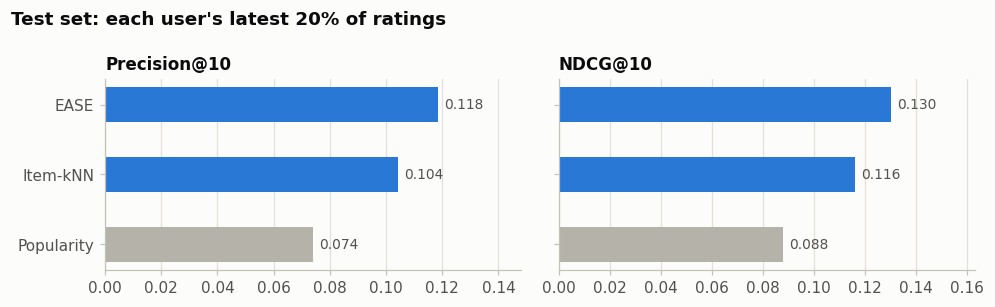

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
order = results.sort_values('NDCG@10').index
for ax, metric in zip(axes, ['Precision@10', 'NDCG@10']):
    values = results.loc[order, metric]
    ax.barh(order, values, height=0.5, color=[GRAY if m == 'Popularity' else BLUE for m in order])
    for i, v in enumerate(values):
        ax.annotate(f'{v:.3f}', (v, i), textcoords='offset points', xytext=(4, 0), va='center', fontsize=9, color=INK2)
    ax.set_xlim(0, values.max() * 1.25)
    ax.set_title(metric, fontsize=11)
    ax.grid(axis='y', visible=False)
fig.suptitle('Test set: each user\'s latest 20% of ratings', x=0.01, ha='left', fontsize=12,
             fontweight='semibold', color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / 'recommender_results.png')
plt.show()

**Result.** EASE fills 11.8% of its top-10 slots with a movie the user went on to rate, against 7.4% for popularity: **+60% Precision@10**, with NDCG@10 at 0.130 vs 0.088. It also spreads recommendations over 7.7% of the catalog instead of 1.2%. Item-kNN lands in between (+42%). On this data, the simple closed-form model is the clear winner.

### What the best model recommends

A sanity check that numbers cannot replace: the movies one user with a typical (median-length) history rated highest in training, next to the model's top 10 for them. Titles marked ✓ are ones the user rated in the test period.

In [8]:
best_name = results.drop(index='Popularity')['NDCG@10'].idxmax()
best = {'Item-kNN': ItemKNN(shrink=best_shrink), 'EASE': EASE(lam=best_lam)}[best_name]
data = Interactions(train)
best.fit(data.X)

history = train.groupby('userId').size()
user = history.sort_values(kind='stable').index[len(history) // 2]  # median-length history
row = data.users.get_loc(user)
scores = best.score(data.X[[row]])[0]
scores[data.X[row].indices] = -np.inf
top10 = data.items[np.argsort(-scores, kind='stable')[:10]]
watched_later = set(test.loc[test.userId == user, 'movieId'])

liked = train[train.userId == user].sort_values(['rating', 'timestamp'], ascending=False).head(10)
pd.DataFrame({
    f'user {user}: rated highest in training': movies.loc[liked.movieId, 'title'].values,
    f'{best_name} top 10': [movies.loc[m, 'title'] + (' ✓' if m in watched_later else '') for m in top10],
})

,user 143: rated highest in training,EASE top 10
0,Uptown Girls (2003),Fight Club (1999)
1,13 Going on 30 (2004),"Princess Bride, The (1987)"
2,50 First Dates (2004),"Monsters, Inc. (2001)"
3,Chasing Liberty (2004),"Dark Knight, The (2008)"
4,Shrek (2001),Avatar (2009)
5,Tangled (2010),"Incredibles, The (2004)"
6,(500) Days of Summer (2009),Ocean's Eleven (2001)
7,"Bill Cosby, Himself (1983)","King's Speech, The (2010)"
8,Sixteen Candles (1984),"Matrix, The (1999)"
9,"Hangover, The (2009)","Sixth Sense, The (1999)"


## How to read the results

- **Popularity is the bar to clear.** In offline tests on movie data, "show everyone the blockbusters" is hard to beat, because blockbusters are what most people watch.
- **Precision@10 looks low in absolute terms** because each user has only a handful of test ratings, and a movie the user would have liked but never rated counts as a miss. Compare models relative to each other, not to 100%.
- **Coverage matters for the business:** a model that recommends the same 20 movies to everyone makes the rest of the catalog invisible.